# Experiment 031: sentinel validation at 7B

What happened after the stopped N=4 seed-1 trajectory was continued from its verified step-100 checkpoint. It compares the continued endpoint with the GSM8K-SFT starting model and the seed-matched N=8 run.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '031_1'
FIG.mkdir(parents=True, exist_ok=True)

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def read_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')

start_dir = RES / '013_COLAB_FULL_B7_sft_grpo_seed1'
continued_dir = RES / '031_COLAB_FULL_B7_external_sft_grpo_seed1'

comparison = jload(RES / '031_comparison_summary.json')
start_eval = jload(start_dir / 'sft_eval.json')
continued_eval = jload(continued_dir / 'grpo_eval.json')
twin_eval = jload(start_dir / 'grpo_eval.json')
start_probe = jload(start_dir / 'sft_logprob.json')
continued_probe = jload(continued_dir / 'grpo_logprob.json')

start_preds = read_jsonl(start_dir / 'sft_preds.jsonl')
continued_preds = read_jsonl(continued_dir / 'grpo_preds.jsonl')
twin_preds = read_jsonl(start_dir / 'grpo_preds.jsonl')
continued_log = pd.DataFrame(jload(continued_dir / 'grpo_trainlog.json'))
twin_log = pd.DataFrame(jload(start_dir / 'grpo_trainlog.json'))

GROUPS = ('overall', 'easy', 'medium', 'hard')
LABELS = ('Overall', 'Easy', 'Medium', 'Hard')
COLORS = {'GSM8K-SFT start': '#9C9C9C', 'N=4 continued': '#F58518', 'N=8 twin': '#4C78A8'}
plt.style.use('seaborn-v0_8-whitegrid')
print('figures ->', FIG.relative_to(ROOT))

figures -> analysis/figures/031_1


## Endpoint comparison

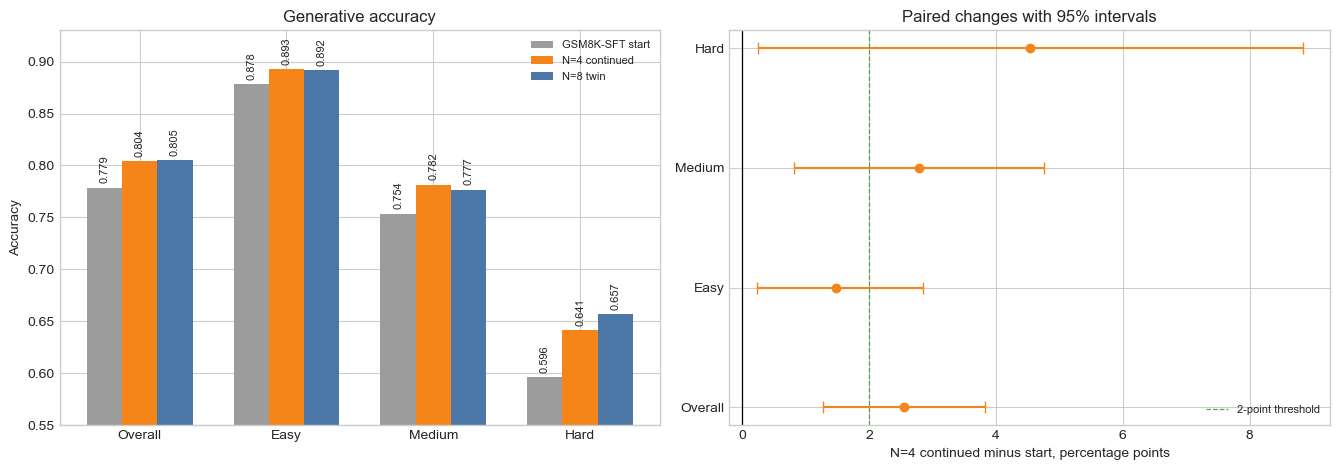

,overall,easy,medium,hard,format rate
model,,,,,
GSM8K-SFT start,0.7787,0.8783,0.7537,0.5960,0.9034
N=4 continued,0.8041,0.8931,0.7816,0.6414,0.9735
N=8 twin,0.8052,0.8919,0.7767,0.6566,0.9889


,delta,ci_low,ci_high
group,,,
overall,2.55,1.27,3.82
easy,1.48,0.23,2.84
medium,2.79,0.82,4.76
hard,4.55,0.25,8.84


In [2]:
def overall(rows):
    return np.mean([row['correct'] for row in rows])

endpoint_rows = []
for name, eval_data, preds in [
    ('GSM8K-SFT start', start_eval, start_preds),
    ('N=4 continued', continued_eval, continued_preds),
    ('N=8 twin', twin_eval, twin_preds),
]:
    endpoint_rows.append({
        'model': name,
        'overall': overall(preds),
        **eval_data['per_tier_acc'],
        'format rate': eval_data['format_compliance'],
    })
endpoint_tbl = pd.DataFrame(endpoint_rows).set_index('model')

delta_rows = []
for group in GROUPS:
    row = comparison['overall'] if group == 'overall' else comparison['tiers_descriptive'][group]
    delta_rows.append({
        'group': group,
        'delta': row['delta'],
        'ci_low': row['ci'][0],
        'ci_high': row['ci'][1],
    })
delta_tbl = pd.DataFrame(delta_rows).set_index('group')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
x = np.arange(len(GROUPS))
width = 0.24
for i, name in enumerate(endpoint_tbl.index):
    values = endpoint_tbl.loc[name, list(GROUPS)].to_numpy(dtype=float)
    bars = axes[0].bar(x + (i - 1) * width, values, width, label=name, color=COLORS[name])
    for bar, value in zip(bars, values):
        axes[0].text(bar.get_x() + bar.get_width() / 2, value + 0.006,
                     f'{value:.3f}', ha='center', fontsize=8, rotation=90)
axes[0].set_xticks(x)
axes[0].set_xticklabels(LABELS)
axes[0].set_ylim(0.55, 0.93)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Generative accuracy')
axes[0].legend(fontsize=8)

y = np.arange(len(GROUPS))
values = delta_tbl['delta'].to_numpy() * 100
low = (delta_tbl['delta'] - delta_tbl['ci_low']).to_numpy() * 100
high = (delta_tbl['ci_high'] - delta_tbl['delta']).to_numpy() * 100
axes[1].errorbar(values, y, xerr=[low, high], fmt='o', color=COLORS['N=4 continued'], capsize=4)
axes[1].axvline(0, color='black', lw=0.9)
axes[1].axvline(2, color='#54A24B', lw=0.9, ls='--', label='2-point threshold')
axes[1].set_yticks(y)
axes[1].set_yticklabels(LABELS)
axes[1].set_xlabel('N=4 continued minus start, percentage points')
axes[1].set_title('Paired changes with 95% intervals')
axes[1].legend(fontsize=8)

fig.tight_layout()
save(fig, 'fig01_endpoint_comparison')
plt.show()
display(endpoint_tbl.round(4))
display((delta_tbl * 100).round(2))

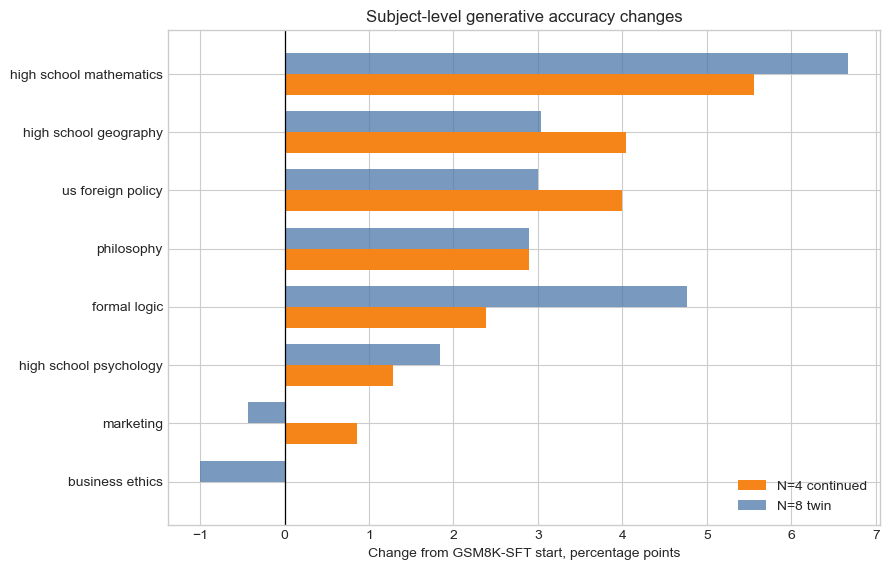

In [3]:
subject_rows = []
for subject in start_eval['per_subject_acc']:
    start = start_eval['per_subject_acc'][subject]
    subject_rows.append({
        'subject': subject,
        'N=4 minus start': continued_eval['per_subject_acc'][subject] - start,
        'N=8 minus start': twin_eval['per_subject_acc'][subject] - start,
    })
subject_tbl = pd.DataFrame(subject_rows).set_index('subject')
subject_tbl = subject_tbl.sort_values('N=4 minus start')

fig, ax = plt.subplots(figsize=(9, 5.8))
y = np.arange(len(subject_tbl))
height = 0.36
ax.barh(y - height / 2, subject_tbl['N=4 minus start'] * 100, height,
        label='N=4 continued', color=COLORS['N=4 continued'])
ax.barh(y + height / 2, subject_tbl['N=8 minus start'] * 100, height,
        label='N=8 twin', color=COLORS['N=8 twin'], alpha=0.75)
ax.axvline(0, color='black', lw=0.9)
ax.set_yticks(y)
ax.set_yticklabels([name.replace('_', ' ') for name in subject_tbl.index])
ax.set_xlabel('Change from GSM8K-SFT start, percentage points')
ax.set_title('Subject-level generative accuracy changes')
ax.legend()
fig.tight_layout()
save(fig, 'fig02_subject_changes')
plt.show()

## Training dynamics

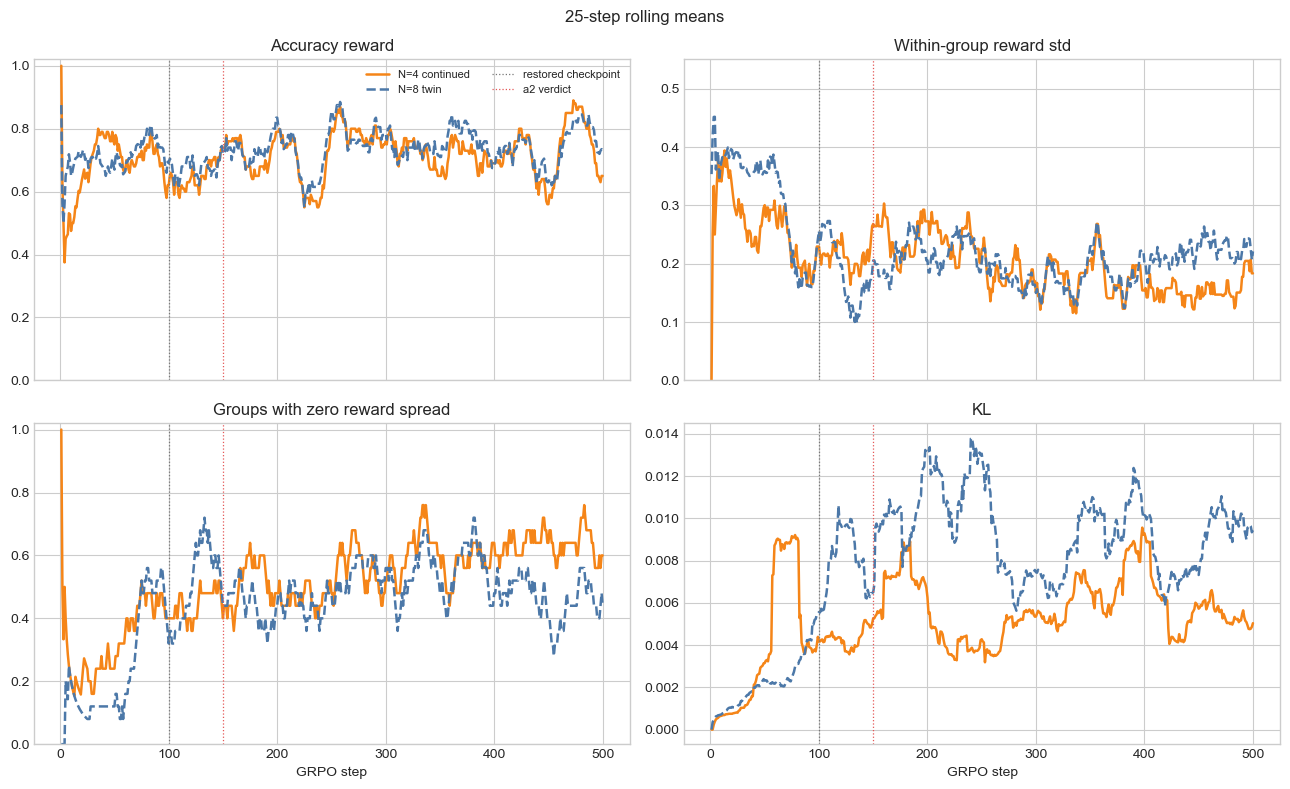

In [4]:
def step_series(frame, metric):
    rows = frame.dropna(subset=['step', metric]).copy()
    rows['step'] = rows['step'].astype(int)
    return rows.groupby('step')[metric].last().sort_index()

metrics = [
    ('rewards/accuracy_reward/mean', 'Accuracy reward', (0, 1.02)),
    ('reward_std', 'Within-group reward std', (0, 0.55)),
    ('frac_reward_zero_std', 'Groups with zero reward spread', (0, 1.02)),
    ('kl', 'KL', None),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, (metric, title, ylim) in zip(axes.flat, metrics):
    for name, frame, style in [
        ('N=4 continued', continued_log, '-'),
        ('N=8 twin', twin_log, '--'),
    ]:
        values = step_series(frame, metric)
        smooth = values.rolling(25, min_periods=1).mean()
        ax.plot(smooth.index, smooth, color=COLORS[name], ls=style, lw=1.8, label=name)
    ax.axvline(100, color='#777777', lw=0.9, ls=':', label='restored checkpoint')
    ax.axvline(150, color='#E45756', lw=0.9, ls=':', label='a2 verdict')
    ax.set_title(title)
    if ylim:
        ax.set_ylim(*ylim)
for ax in axes[1]:
    ax.set_xlabel('GRPO step')
axes[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle('25-step rolling means')
fig.tight_layout()
save(fig, 'fig03_training_dynamics')
plt.show()

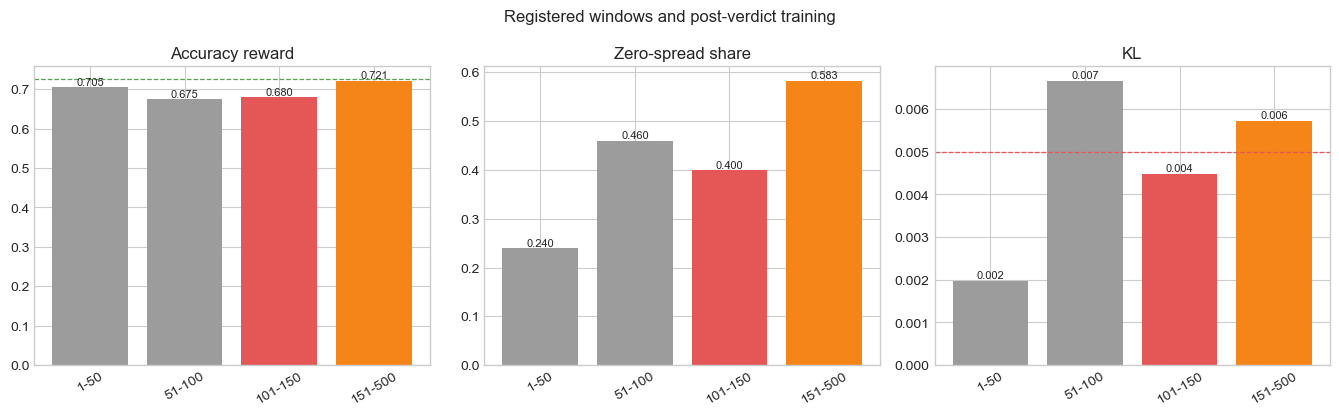

,rewards/accuracy_reward/mean,rewards/format_reward/mean,frac_reward_zero_std,reward_std,kl
1-50,0.7050,0.175,0.2400,0.2955,0.0020
51-100,0.6750,0.187,0.4600,0.2113,0.0067
101-150,0.6800,0.180,0.4000,0.2394,0.0045
151-500,0.7214,0.189,0.5829,0.1843,0.0057


In [5]:
windows = pd.DataFrame(comparison['training_windows']).T
windows.index = ['1-50', '51-100', '101-150', '151-500']

panels = [
    ('rewards/accuracy_reward/mean', 'Accuracy reward'),
    ('frac_reward_zero_std', 'Zero-spread share'),
    ('kl', 'KL'),
]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
for ax, (metric, title) in zip(axes, panels):
    bars = ax.bar(windows.index, windows[metric], color=['#9C9C9C', '#9C9C9C', '#E45756', '#F58518'])
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)
    for bar, value in zip(bars, windows[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.3f}',
                ha='center', va='bottom', fontsize=8)
axes[0].axhline(comparison['a2_verdict']['early_accuracy_reward_mean'] +
                comparison['a2_verdict']['min_improvement'], color='#54A24B', ls='--', lw=0.9)
axes[2].axhline(comparison['a2_verdict']['max_mid_kl'], color='#E45756', ls='--', lw=0.9)
fig.suptitle('Registered windows and post-verdict training')
fig.tight_layout()
save(fig, 'fig04_training_windows')
plt.show()
display(windows.round(4))

## Exact values

In [6]:
summary_tbl = pd.DataFrame({
    'value': {
        'a2 would fire': comparison['a2_verdict']['would_fire'],
        'overall start': comparison['overall']['reference_acc'],
        'overall N=4 continued': comparison['overall']['continued_acc'],
        'overall delta': comparison['overall']['delta'],
        'overall CI low': comparison['overall']['ci'][0],
        'overall CI high': comparison['overall']['ci'][1],
        'overall McNemar p': comparison['overall']['mcnemar_p'],
        'hard delta': comparison['tiers_descriptive']['hard']['delta'],
        'probe delta': comparison['probe_descriptive']['delta'],
        'N=8 twin overall': comparison['n8_twin_overall_descriptive'],
        'format start': comparison['format_rate']['start'],
        'format continued': comparison['format_rate']['continued'],
    }
})

endpoint_tbl.to_csv(FIG / 'endpoint_accuracy.csv')
delta_tbl.to_csv(FIG / 'paired_changes.csv')
subject_tbl.to_csv(FIG / 'subject_changes.csv')
windows.to_csv(FIG / 'training_windows.csv')
summary_tbl.to_csv(FIG / 'summary_values.csv')

display(summary_tbl.round(4))
print('registered outcome:', comparison['registered_outcome'])
print('endpoint contact:', comparison['endpoint_contact'])

,value
a2 would fire,True
overall start,0.778662
overall N=4 continued,0.80414
overall delta,0.025478
overall CI low,0.012739
overall CI high,0.038217
overall McNemar p,0.000122
hard delta,0.045455
probe delta,0.002654
N=8 twin overall,0.805202


registered outcome: material improvement
endpoint contact: 2


## Cross-referenced conclusion

The a2 stop was reproduced at step 150, but continuing the same trajectory to step 500 improved overall generative accuracy from 77.87% to 80.41%. The gain was +2.55 points, with a 95% interval from +1.27 to +3.82 points.

Hard accuracy increased by 4.55 points, while probe accuracy changed by only 0.27 points. The N=4 endpoint was also close to the seed-matched N=8 result, 80.41% versus 80.52%. This means the a2 rule stopped a trajectory that later reached a useful endpoint, but the conclusion is exploratory and specific to this seed and checkpoint.